# 288: Is Ced9 → BCL2 significant as a pairwise question, and can a two-step search use it?

[Notebook 284](https://github.com/seanome/2024-kmerseek-analysis/pull/125) found that
Ced9's best kmerseek calls on BCL2, searched against the 19_732 GENCODE v49 canonical human
proteins, have E = 1_955 (BCL2's BH4 motif, wwmj5 k = 9) and E = 11_173 (BH1,
hp_lehninger2 k = 19). An E-value is the number of regions this good that chance would give
in a search of this size, so those calls are noise at proteome scale. Two questions:

1. **Pairwise.** If the question is only "is Ced9 related to BCL2?", the search space is one
   protein, not 19_732. What E-value does kmerseek give then, and does it beat what Ced9's
   shuffled copies get?
2. **Two-step.** Can a search that first picks a short list of candidate proteins and then
   scores only those find BCL2 for Ced9 with honest E-values? Picking the list from the same
   search favours proteins that already scored well, so the shuffled copies go through the
   same two steps and measure that bias.

The same two questions are asked of P66 and CD47.

**Decision this informs.** Whether the paper can say "kmerseek finds Ced9 → BCL2" in any
form. A pass on question 1 allows "Ced9 and BCL2 are significantly similar as a pair under
kmerseek" but not "kmerseek finds BCL2 in a proteome search". A pass on question 2 makes a
two-step search a mode worth building into kmerseek. A fail on both means the Ced9 → BCL2
example shows only what kmerseek cannot do.

**Decision rules, written before any search ran (commit 25d69f9, 2026-10-13).**

*Question 1.* A **setting** is one kmerseek alphabet at one k-mer size, with notebook 241's
index and search flags; 70 of 241's 152 settings have a fitted E-value. The real query's best
pairwise E-value over the 70 settings is compared with the best for each of 100 dipeptide
shuffles of the query (same length, same count of every adjacent residue pair, so no real
homology). Pass: best pairwise E < 0.05, and empirical p = (1 + shuffles with a best E at or
below the real query's) / 101 < 0.05.

*Question 2.* Step 1 picks candidates without using the answer:
- rule A50: the 50 human proteins with the lowest best E-value over the 70 settings;
- rule B: every human protein with a region at E < 10 (BLAST's default reporting cut) at 3
  or more of the 70 settings.

Step 2 re-scores only the candidates, with the database size set to the candidates' k-mer
count. Pass: the partner is a candidate, its best step-2 E < 0.05, and at most 4 of the 100
shuffles (under 5%) have any candidate with step-2 E < 0.05.

**Data.** Queries: Ced9 (*C. elegans*, 280 aa) and P66 (*Borrelia burgdorferi*, 597 aa) from
notebook 241's `queries.fa` (md5 fc9ac30a7773b921c086c1684d4b631f). Target databases: the
GENCODE v49 canonical human translations (19_732 proteins, md5
e68d27427d1b119d9ca1999803fa20e9), and indexes of BCL2 alone, CD47 alone, and the 14 human
BCL-2 family proteins of HGNC gene group 1057 (fetched 2026-10-13). kmerseek 0.4.0 at commit
982a055, the build of notebooks 241, 256 and 283. The proteome-search rows read here are
notebook 241's own output on Sherlock (`$SCRATCH/241-alphabet-ranking/search`), copied to
`data/288/241_ced9_p66_regions_on_bcl2_family_cd47.csv.gz`.

In [1]:
import sys
import importlib.util
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

sys.path.insert(0, ".")
import pubfig as pf

pf.use_style()


def plain_log_ticks(ax, which="y"):
    # plain numbers (0.01, 1, 1000) on a log axis instead of 10^x
    from matplotlib.ticker import FuncFormatter, LogLocator

    fmt = FuncFormatter(
        lambda v, _: f"{v:,.0f}".replace(",", "_") if v >= 1 else f"{v:g}"
    )
    axes = [ax.xaxis, ax.yaxis] if which == "both" else [ax.yaxis]
    for a in axes:
        a.set_major_locator(LogLocator(base=10, numticks=12))
        a.set_major_formatter(fmt)


pl.Config.set_tbl_rows(80)
pl.Config.set_tbl_cols(20)
pl.Config.set_fmt_str_lengths(60)
pl.Config.set_tbl_width_chars(200)

DATA = Path("../data/288")
FIG = Path("../figures")
spec = importlib.util.spec_from_file_location("nb288", "288_two_step_search.py")
nb288 = importlib.util.module_from_spec(spec)
spec.loader.exec_module(nb288)

PASS_E = nb288.PASS_E
PARTNER = nb288.PARTNER
family = sorted(
    d["symbol"]
    for d in __import__("json").loads(
        (DATA / "hgnc_gene_group_1057_bcl2_family.json").read_text()
    )["response"]["docs"]
)
seqs = {
    h.split("|")[6]: s
    for h, s in nb288.read_fasta(
        DATA / "gencode_v49_canonical_bcl2_family_cd47.fa"
    ).items()
}
queries = nb288.read_fasta(Path("../data/288/queries_241.fa"))
print("BCL-2 family (HGNC group 1057):", len(family), family)
print("query lengths:", {q: len(s) for q, s in queries.items()})

rows = pl.read_csv(
    DATA / "241_ced9_p66_regions_on_bcl2_family_cd47.csv.gz", infer_schema_length=0
)
num = [
    c
    for c in rows.columns
    if c.startswith(("region_", "db_", "target_start", "target_end"))
    and not c.endswith("subseq")
]
rows = rows.with_columns(
    *[pl.col(c).cast(pl.Float64) for c in num],
    gene=pl.col("target_name").str.split("|").list.get(6),
    alphabet=pl.col("setting").str.split(".k").list.get(0),
    k=pl.col("setting").str.split(".k").list.get(1).cast(pl.Int64),
).with_columns(query_length=pl.col("region_search_space") + pl.col("k") - 1)
print(
    rows.height,
    "region rows from notebook 241:",
    rows.group_by("query_name").len().sort("query_name").rows(),
)
print(
    rows["setting"].n_unique(),
    "settings have a Ced9 or P66 region on these 15 proteins",
)
fits = pl.read_csv(DATA / "settings_241_fitted.csv")
print(
    fits.height,
    "settings with a human Karlin-Altschul fit;",
    (fits["fit_file"].str.contains("retry")).sum(),
    "of those fits came from 241's retry",
)

BCL-2 family (HGNC group 1057): 14 ['BAK1', 'BAX', 'BCL2', 'BCL2A1', 'BCL2L1', 'BCL2L10', 'BCL2L12', 'BCL2L13', 'BCL2L14', 'BCL2L15', 'BCL2L2', 'BNIP2', 'BOK', 'MCL1']
query lengths: {'Ced9': 280, 'P66': 597, 'BHF': 252}
2174 region rows from notebook 241: [('Ced9', 987), ('P66', 1187)]
44 settings have a Ced9 or P66 region on these 15 proteins
70 settings with a human Karlin-Altschul fit; 11 of those fits came from 241's retry


## 1. What kmerseek's region E-value counts

kmerseek 982a055, `src/rust/search.rs`:

```rust
1690  let m = q_enc.len() as f64;          // the query's length, encoded, in residues
1691  let n = self.db_n_kmers as f64;        // the database's k-mer count
...
1705  region.ka_bits = ((region.ka_lambda * raw - params.ka_k.ln()) / LN_2).max(0.0);
1708  region.evalue = params.ka_k * m * n * (-region.ka_lambda * raw).exp();
```

and `db_n_kmers` is set at line 1240 to `stats.kmer_frequencies.values().sum()`, where
`kmer_frequencies` maps each indexed k-mer to the number of target proteins that hold it
(`src/rust/index.rs:1259`). So:

```text
E = K × m × n × exp(−λ × S)

m = the query's length (Ced9: 280 residues, the whole protein, not the region)
n = the sum over every target protein of its distinct k-mers after the low-complexity mask
    (about one per residue; not the residue count and not the number of proteins)
K, λ = the Karlin-Altschul constants; λ is the closed-form value for the region's own
       residue-class make-up, times a scale fitted on the index (search.rs:1700-1701)
S = matches − penalty × mismatches over the region
```

Nothing in E depends on the database except n and the fitted K and λ scale, and the region
itself comes from the query and that one target. So the same region against a smaller
database has E smaller by n_small / n_human, as long as K and the λ scale are kept from the
human fit. A database of one or 14 proteins is too small for kmerseek to fit K itself
(`resolve_ka` in search.rs refuses an E-value without a fit), so the Sherlock run borrows
the human K with `--ka-k` and puts the human λ scale back from the output columns: `--ka-k`
sets the scale to 1 (search.rs, `KaSource::Flag`).

Since the bit score is (λS − ln K) / ln 2, the formula also reads E = m × n × 2^(−bits).
The cell below checks that on every one of notebook 241's rows (Ced9 and P66 on the 14
BCL-2 family proteins and CD47, 70 settings).

309 of 2174 rows have bits > 0 (the rest have lambda 0: E is infinite)
largest relative difference between kmerseek's E and m * n * 2^-bits: 3.22e-15
m (query length) per query: [('Ced9', [280.0]), ('P66', [597.0])]
largest relative difference between K recovered from a row and the fitted K in settings_241_fitted.csv: 4.44e-15 (29 settings)
n_human per setting (one value each): True
shape: (1, 2)
┌──────────────────┬─────────────────┐
│ smallest n_human ┆ largest n_human │
│ ---              ┆ ---             │
│ f64              ┆ f64             │
╞══════════════════╪═════════════════╡
│ 9.616741e6       ┆ 1.1002012e7     │
└──────────────────┴─────────────────┘


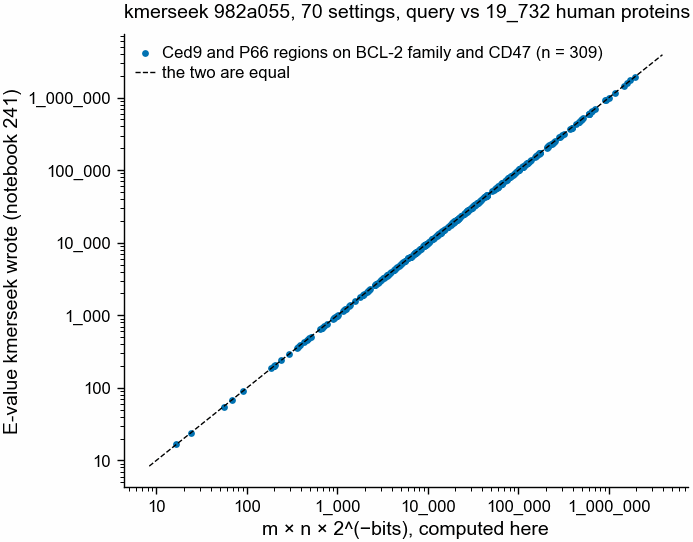

In [2]:
chk = (
    rows.filter(pl.col("region_ka_bits") > 0)
    .with_columns(
        e_from_bits=pl.col("query_length")
        * pl.col("db_n_kmers")
        * (2.0 ** -pl.col("region_ka_bits"))
    )
    .with_columns(rel_diff=(pl.col("e_from_bits") / pl.col("region_evalue") - 1).abs())
)
print(
    f"{chk.height} of {rows.height} rows have bits > 0 (the rest have lambda 0: E is infinite)"
)
print(
    f"largest relative difference between kmerseek's E and m * n * 2^-bits: {chk['rel_diff'].max():.2e}"
)
print(
    "m (query length) per query:",
    chk.group_by("query_name").agg(pl.col("query_length").unique()).rows(),
)
# K from each row: bits = (lambda S - ln K) / ln 2, so K = exp(lambda S - bits ln 2)
kchk = (
    chk.join(fits.select("setting", "penalty", "ka_k"), on="setting")
    .with_columns(
        S=(pl.col("region_length") - pl.col("region_n_mismatches"))
        - pl.col("penalty") * pl.col("region_n_mismatches")
    )
    .with_columns(
        k_from_row=(
            pl.col("region_ka_lambda") * pl.col("S")
            - pl.col("region_ka_bits") * np.log(2)
        ).exp()
    )
)
print(
    f"largest relative difference between K recovered from a row and the fitted K in settings_241_fitted.csv: "
    f"{(kchk['k_from_row'] / kchk['ka_k'] - 1).abs().max():.2e} ({kchk['setting'].n_unique()} settings)"
)
n_tab = (
    rows.group_by("setting")
    .agg(n_human=pl.col("db_n_kmers").first(), n_values=pl.col("db_n_kmers").n_unique())
    .sort("n_human")
)
print("n_human per setting (one value each):", n_tab["n_values"].max() == 1)
print(
    n_tab.select(
        pl.col("n_human").min().alias("smallest n_human"),
        pl.col("n_human").max().alias("largest n_human"),
    )
)

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 70)
ax.scatter(
    chk["e_from_bits"],
    chk["region_evalue"],
    s=6,
    color=pf.OKABE_ITO["blue"],
    lw=0,
    label=f"Ced9 and P66 regions on BCL-2 family and CD47 (n = {chk.height})",
)
lo, hi = chk["region_evalue"].min() / 2, chk["region_evalue"].max() * 2
ax.plot([lo, hi], [lo, hi], color="black", lw=0.5, ls="--", label="the two are equal")
ax.set_xscale("log")
ax.set_yscale("log")
plain_log_ticks(ax, "both")
ax.set_xlabel("m × n × 2^(−bits), computed here")
ax.set_ylabel("E-value kmerseek wrote (notebook 241)")
ax.legend(loc="upper left", frameon=False)
ax.set_title(
    "kmerseek 982a055, 70 settings, query vs 19_732 human proteins", loc="left"
)
pf.save(fig, FIG / "288_evalue_formula_check_gencode_v49")

Every row matches to rounding, so E = m × n × 2^(−bits), with m the whole query's length and
n the human index's k-mer count, 9.6 to 11.0 million across the settings shown (printed
above). That is close to the 11_347_201 residues the task's arithmetic used, but smaller,
because each protein loses k − 1 windows at its end and the low-complexity mask drops more.

## 2. The pairwise E-value each setting predicts

For every setting, Ced9's best region on BCL2 (lowest E in notebook 241's proteome search)
and P66's best region on CD47, rescaled to three small databases:

```text
E_pair = E_human × n_small / n_human
```

n_small is counted here as kmerseek counts it (`distinct_kmers` in
`288_two_step_search.py`, following `sketch.rs:466-520`: distinct encoded k-mers, dropping
windows of one repeated residue, and for alphabets with a class table and hp_lehninger2 also
windows whose encoded letters are all the same). For the BCL-2 family index, n_small is the
sum over the 14 proteins, and the E-value is that of Ced9's best region on any of them.
**These are predictions**: the Sherlock run (section 3) builds the small indexes, reads
kmerseek's own `db_n_kmers`, and checks both.

In [3]:
settings = fits.select("setting", "alphabet", "k", "n_human")


def n_small(genes):
    return pl.DataFrame(
        [
            {
                "setting": s,
                "n_small": sum(nb288.distinct_kmers(seqs[g], a, k) for g in genes),
            }
            for s, a, k in settings.select("setting", "alphabet", "k").iter_rows()
        ]
    )


dbs = {"BCL2 alone": ["BCL2"], "BCL-2 family (14)": family, "CD47 alone": ["CD47"]}
n_db = pl.concat([n_small(g).with_columns(database=pl.lit(d)) for d, g in dbs.items()])


def best_on(query, genes):
    # lowest E per setting; ties broken by the region's position, so the pick is fixed
    return (
        rows.filter((pl.col("query_name") == query) & pl.col("gene").is_in(genes))
        .sort("region_evalue", "gene", "region_start", "target_start")
        .group_by("setting", maintain_order=True)
        .first()
    )


pred = []
for q, d in [
    ("Ced9", "BCL2 alone"),
    ("Ced9", "BCL-2 family (14)"),
    ("P66", "CD47 alone"),
]:
    b = best_on(q, dbs[d]).join(n_db.filter(pl.col("database") == d), on="setting")
    pred.append(
        b.with_columns(
            query=pl.lit(q),
            e_human=pl.col("region_evalue"),
            e_pair_predicted=pl.col("region_evalue")
            * pl.col("n_small")
            / pl.col("db_n_kmers"),
        )
    )
pred = (
    pl.concat(pred)
    .select(
        "query",
        "database",
        "setting",
        "alphabet",
        "k",
        "gene",
        (pl.col("region_start") + 1).cast(pl.Int64).alias("query_from"),
        pl.col("region_end").cast(pl.Int64).alias("query_to"),
        (pl.col("target_start") + 1).cast(pl.Int64).alias("target_from"),
        pl.col("target_end").cast(pl.Int64).alias("target_to"),
        pl.col("region_n_mismatches").cast(pl.Int64).alias("mismatches"),
        pl.col("region_ka_bits").alias("bits"),
        pl.col("db_n_kmers").cast(pl.Int64).alias("n_human"),
        "n_small",
        "e_human",
        "e_pair_predicted",
    )
    .sort("query", "database", "e_pair_predicted")
)
pred.write_csv("288_pairwise_evalue_predicted.csv")

summary = (
    pred.group_by("query", "database")
    .agg(
        n_settings_with_region=pl.len(),
        n_settings_e_finite=(pl.col("e_pair_predicted").is_finite()).sum(),
        best_e_pair_predicted=pl.col("e_pair_predicted").min(),
        n_settings_below_005=(pl.col("e_pair_predicted") < PASS_E).sum(),
    )
    .sort("query", "database")
)
print("Coordinates are 1-based and inclusive (kmerseek writes 0-based, end-exclusive).")
print(summary)
print(pred.group_by("query", "database", maintain_order=True).head(5))

Coordinates are 1-based and inclusive (kmerseek writes 0-based, end-exclusive).
shape: (3, 6)
┌───────┬───────────────────┬────────────────────────┬─────────────────────┬───────────────────────┬──────────────────────┐
│ query ┆ database          ┆ n_settings_with_region ┆ n_settings_e_finite ┆ best_e_pair_predicted ┆ n_settings_below_005 │
│ ---   ┆ ---               ┆ ---                    ┆ ---                 ┆ ---                   ┆ ---                  │
│ str   ┆ str               ┆ u32                    ┆ u32                 ┆ f64                   ┆ u32                  │
╞═══════╪═══════════════════╪════════════════════════╪═════════════════════╪═══════════════════════╪══════════════════════╡
│ Ced9  ┆ BCL-2 family (14) ┆ 42                     ┆ 24                  ┆ 0.005184              ┆ 4                    │
│ Ced9  ┆ BCL2 alone        ┆ 20                     ┆ 6                   ┆ 0.041359              ┆ 1                    │
│ P66   ┆ CD47 alone        ┆ 23      

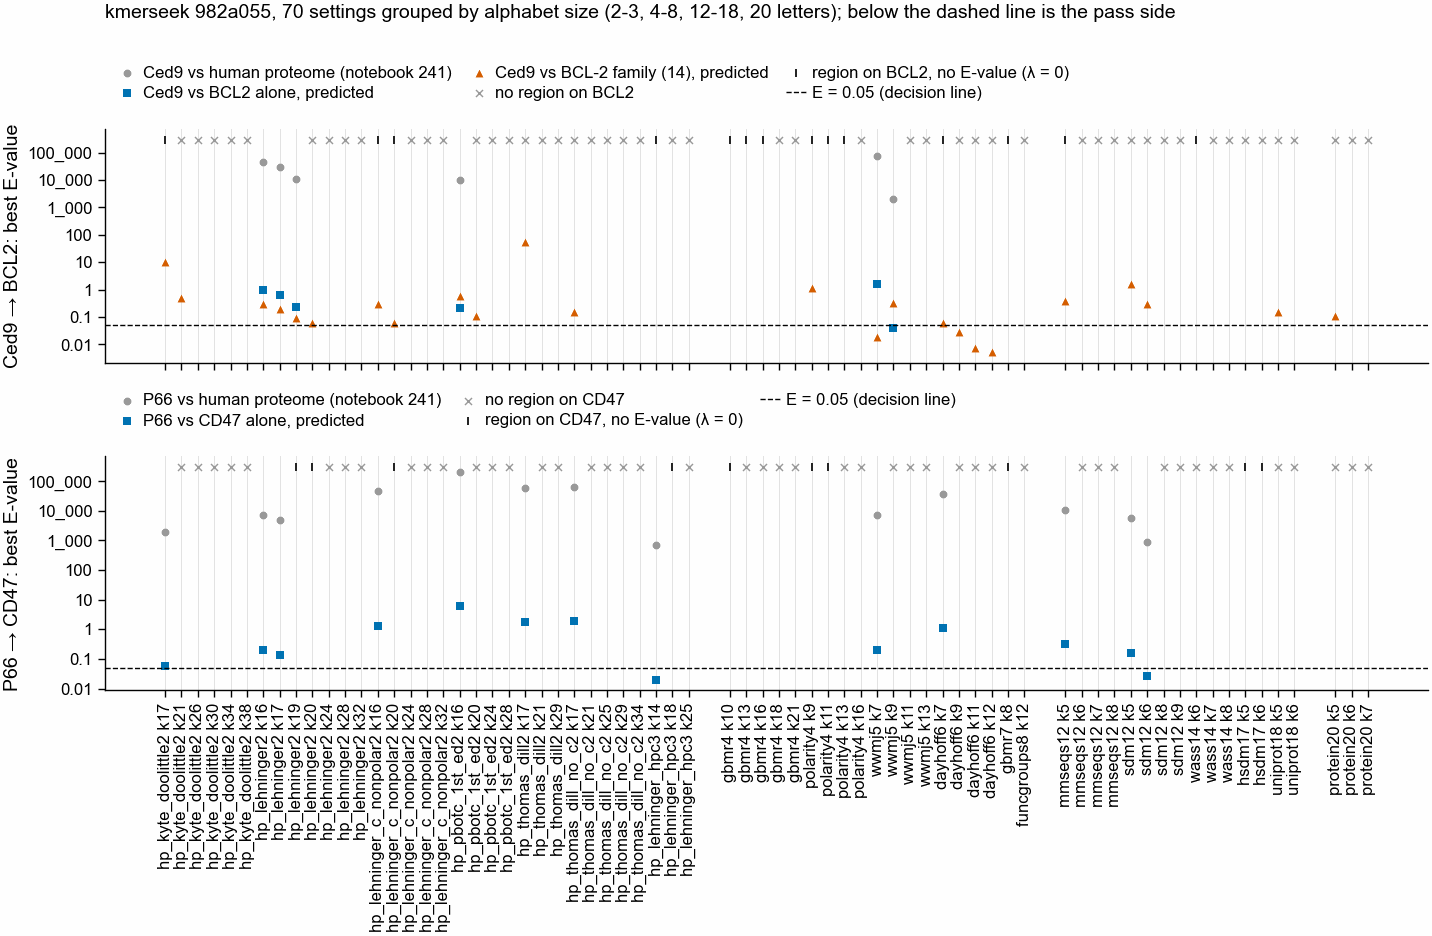

In [4]:
SIZE_GROUPS = [(2, 3), (4, 8), (12, 18), (20, 20)]
n_classes = {a: len(c) for a, c in nb288.CLUSTERS.items()}
order = sorted(
    settings.rows(named=True),
    key=lambda r: (
        next(
            i
            for i, (lo, hi) in enumerate(SIZE_GROUPS)
            if lo <= n_classes[r["alphabet"]] <= hi
        ),
        n_classes[r["alphabet"]],
        r["alphabet"],
        r["k"],
    ),
)
xpos, x, prev_group = {}, 0, None
for r in order:
    g = next(
        i
        for i, (lo, hi) in enumerate(SIZE_GROUPS)
        if lo <= n_classes[r["alphabet"]] <= hi
    )
    if prev_group is not None and g != prev_group:
        x += 1.5  # gap between alphabet-size groups
    xpos[r["setting"]] = x
    x += 1
    prev_group = g

marks = {  # one colour and shape per database
    "human proteome (19_732)": dict(color=pf.GREY, marker="o"),
    "BCL2 alone": dict(color=pf.OKABE_ITO["blue"], marker="s"),
    "BCL-2 family (14)": dict(color=pf.OKABE_ITO["vermillion"], marker="^"),
    "CD47 alone": dict(color=pf.OKABE_ITO["blue"], marker="s"),
}
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 120, nrows=2, sharex=True)
for ax, (q, partner, dbl) in zip(
    axs,
    [
        ("Ced9", "BCL2", ["BCL2 alone", "BCL-2 family (14)"]),
        ("P66", "CD47", ["CD47 alone"]),
    ],
):
    hum = pred.filter((pl.col("query") == q) & (pl.col("database") == dbl[0]))
    fin = pl.col("e_pair_predicted").is_finite()
    hf = hum.filter(fin)
    ax.scatter(
        [xpos[s] for s in hf["setting"]],
        hf["e_human"],
        s=8,
        lw=0,
        label=f"{q} vs human proteome (notebook 241)",
        **marks["human proteome (19_732)"],
    )
    for d in dbl:
        p = pred.filter((pl.col("query") == q) & (pl.col("database") == d) & fin)
        ax.scatter(
            [xpos[s] for s in p["setting"]],
            p["e_pair_predicted"],
            s=8,
            lw=0,
            label=f"{q} vs {d}, predicted",
            **marks[d],
        )
    top = 3e5  # row of the two "no value" marks, above every E-value drawn
    missing = [s for s in xpos if s not in set(hum["setting"])]
    ax.scatter(
        [xpos[s] for s in missing],
        [top] * len(missing),
        marker="x",
        s=6,
        lw=0.5,
        color=pf.GREY,
        label=f"no region on {partner}",
    )
    noe = hum.filter(~pl.col("e_human").is_finite())["setting"]
    ax.scatter(
        [xpos[s] for s in noe],
        [top] * len(noe),
        marker="|",
        s=10,
        lw=0.6,
        color="black",
        label=f"region on {partner}, no E-value (λ = 0)",
    )
    ax.axhline(PASS_E, color="black", lw=0.5, ls="--", label="E = 0.05 (decision line)")
    ax.set_yscale("log")
    plain_log_ticks(ax)
    ax.set_ylabel(f"{q} → {partner}: best E-value")
    ax.legend(loc="upper left", bbox_to_anchor=(0, 1.32), ncol=3, frameon=False)
    for s, xx in xpos.items():
        ax.axvline(xx, color="#dddddd", lw=0.3, zorder=0)
axs[-1].set_xticks(list(xpos.values()))
axs[-1].set_xticklabels([s.replace(".k", " k") for s in xpos], rotation=90)
axs[0].set_title(
    "kmerseek 982a055, 70 settings grouped by alphabet size (2-3, 4-8, 12-18, 20 letters); "
    "below the dashed line is the pass side",
    loc="left",
    pad=40,
)
pf.save(fig, FIG / "288_pairwise_evalue_predicted_ced9_bcl2_p66_cd47_gencode_v49")

## 3. The real residues of the best predicted pairs

Each pair's best setting from section 2, as kmerseek aligned it (ungapped). The match line
marks identical residues (`|`) and residues in the same class of that alphabet (`+`); the
encoded strings underneath use the alphabet's classes in the order of `CLUSTERS`
(a = first class).

In [5]:
def show(q, d):
    r = pred.filter((pl.col("query") == q) & (pl.col("database") == d)).row(
        0, named=True
    )
    full = rows.filter(
        (pl.col("query_name") == q)
        & (pl.col("setting") == r["setting"])
        & (pl.col("gene") == r["gene"])
        & (pl.col("region_start") == r["query_from"] - 1)
        & (pl.col("target_start") == r["target_from"] - 1)
    ).row(0, named=True)
    a, b = full["region_subseq"], full["target_subseq"]
    enc = nb288.encoder(r["alphabet"])
    ea, eb = "".join(enc[c] for c in a), "".join(enc[c] for c in b)
    line = "".join(
        "|" if x == y else ("+" if enc[x] == enc[y] else " ") for x, y in zip(a, b)
    )
    eline = "".join("|" if x == y else " " for x, y in zip(ea, eb))
    print(
        f"{q} vs {r['gene']} ({d}), {r['alphabet']} k = {r['k']}: "
        f"{sum(x == y for x, y in zip(a, b))} of {len(a)} residues identical, "
        f"{r['mismatches']} class mismatches; E human {r['e_human']:.4g}, "
        f"E pairwise predicted {r['e_pair_predicted']:.3g}"
    )
    w = max(len(q), len(r["gene"])) + 1
    print(f"  {q:<{w}}{r['query_from']:>5} {a} {r['query_to']}")
    print(f"  {'':<{w}}{'':>5} {line}")
    print(f"  {r['gene']:<{w}}{r['target_from']:>5} {b} {r['target_to']}")
    print(f"  {'encoded':<{w}}{'':>5} {ea}")
    print(f"  {'':<{w}}{'':>5} {eline}")
    print(f"  {'':<{w}}{'':>5} {eb}\n")


for q, d in [
    ("Ced9", "BCL2 alone"),
    ("Ced9", "BCL-2 family (14)"),
    ("P66", "CD47 alone"),
]:
    show(q, d)

Ced9 vs BCL2 (BCL2 alone), wwmj5 k = 9: 7 of 22 residues identical, 5 class mismatches; E human 1955, E pairwise predicted 0.0414
  Ced9    78 LDIEGFVVDYFTHRIRQNGMEW 99
             +|   +|+ |++ +++|+|+||
  BCL2     9 YDNREIVMKYIHYKLSQRGYEW 30
  encoded      adadcaaadaabbeaeeecada
             ||   ||| ||| |||||||||
             adeedaaaeaabaeaeeecada

Ced9 vs MCL1 (BCL-2 family (14)), dayhoff6 k = 12: 10 of 18 residues identical, 1 class mismatches; E human 16.69, E pairwise predicted 0.00518
  Ced9   168 YGRLIGLISFGGFVAAKM 185
             +||+++|||||+||| ++
  MCL1   261 WGRIVTLISFGAFVAKHL 278
  encoded      fbdeebeebfbbfebbde
             ||||||||||||||| ||
             fbdeebeebfbbfebdde

P66 vs CD47 (CD47 alone), hp_lehninger_hpc3 k = 14: 2 of 30 residues identical, 6 class mismatches; E human 707.4, E pairwise predicted 0.0198
  P66      9 IFKINPWMPTFGFENTSEFRLDMDELVPGF 38
             ++++  + ++++|++|+++++++ +  +++
  CD47    10 LGSACCGSAQLLFNKTKSVEFTFCNDTVVI 39
  encoded      aa

## Summary so far (2026-10-13, before the Sherlock runs)

**Measured.**
- kmerseek's region E-value is K × m × n × exp(−λS), with m the whole query's length and n
  the database's k-mer count (`search.rs:1690-1708`). On all 309 of notebook 241's Ced9 and
  P66 regions on the BCL-2 family and CD47 that have an E-value, E = m × n × 2^(−bits) to
  within 3e-15, and the K recovered from each row equals the fitted K of its setting.
- n is the human index's k-mer count, 9.6 to 11.0 million, not the 11_347_201 residues.

**Predicted, not yet run** (E_human × n_small / n_human, with n_small counted as kmerseek
counts it):
- Ced9 vs BCL2 alone: best E = 0.041 (wwmj5 k = 9, Ced9 78-99 on BCL2's BH4 at 9-30). One
  of the 70 settings is below 0.05; at 64 settings Ced9 has no region on BCL2 with an
  E-value.
- Ced9 vs the 14-protein BCL-2 family: best E = 0.0052 (dayhoff6 k = 12, Ced9 168-185 on
  MCL1's BH1 at 261-278); 4 settings below 0.05.
- P66 vs CD47 alone: best E = 0.020 (hp_lehninger_hpc3 k = 14, P66 9-38 on CD47 10-39,
  2 of 30 residues identical); 2 settings below 0.05.

**Not yet decided.** Each of these is the best of 70 settings. Under the decision rule a pass
also needs fewer than 5% of 100 shuffled copies to reach the same best E, and a best of 70
can fall below 0.05 by chance. The shuffle searches against the small indexes (question 1)
and the two-step test (question 2) run on Sherlock with `288_two_step_search.sbatch`; the
sections that read their output are added when they finish.